# Home Loan Default Prediction

## Complete Data Analysis and Predictive Modeling Report

### Business Objective
Analyze home-loan application and historical credit data, identify factors associated with observed defaults, and build a model that estimates default risk. The result can support customer-risk segmentation and additional application review. It does **not** determine loan eligibility by itself.

### Target Definition
- `TARGET = 0`: no recorded default in the dataset.
- `TARGET = 1`: recorded default in the dataset.

### Data Sources
`application_train.csv` is the main application-level dataset. The notebook also summarizes `bureau.csv`, `bureau_balance.csv`, `previous_application.csv`, `POS_CASH_balance.csv`, `credit_card_balance.csv`, and `installments_payments.csv` by `SK_ID_CURR` before joining the summaries to the main table.

### Reproducibility and Setup
Place all seven CSV files in the same folder as this notebook. Required packages include `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `imbalanced-learn`, and `xgboost`. Install missing packages in your environment before running the notebook. Run cells from top to bottom in a fresh kernel; historical aggregation and model tuning may take time and memory.

**Responsible-use note:** This is a portfolio/client-project analysis, not a validated lending system. Model predictions should support human review and must not be the sole basis for approving or rejecting a loan. Fairness, calibration, legal compliance, and external validation are required before any real-world use.

## 1. Import Libraries

In [1]:
#  Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve,
    precision_recall_curve
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

print("Libraries imported successfully")

Libraries imported successfully


## 2. Load Dataset

The main application file contains one row per loan application. The other files are used to create customer-level summaries of historical behavior.

In [2]:
df = pd.read_csv("application_train.csv")

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Dataset loaded successfully.
Rows: 307511
Columns: 122


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Basic Data Understanding

In [3]:
print("Dataset dimensions:", df.shape)

Dataset dimensions: (307511, 122)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [5]:
df.columns

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY',
       ...
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='object', length=122)

In [6]:
display(df.describe())

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [7]:
print("Missing values in the main dataset:", df.isnull().sum().sum())

Missing values in the main dataset: 9152465


In [8]:
print("Missing values:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .head(20)
)

Missing values:


COMMONAREA_MEDI             214865
COMMONAREA_AVG              214865
COMMONAREA_MODE             214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_AVG     213514
NONLIVINGAPARTMENTS_MEDI    213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_MODE       210199
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
FLOORSMIN_AVG               208642
FLOORSMIN_MODE              208642
FLOORSMIN_MEDI              208642
YEARS_BUILD_MEDI            204488
YEARS_BUILD_MODE            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
LANDAREA_AVG                182590
dtype: int64

In [9]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["SK_ID_CURR"].duplicated().sum())
print("Unique customer IDs:", df["SK_ID_CURR"].nunique())
print("Target distribution:")
display(df["TARGET"].value_counts())

Duplicate rows: 0
Duplicate customer IDs: 0
Unique customer IDs: 307511
Target distribution:


TARGET
0    282686
1     24825
Name: count, dtype: int64

## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand target balance, missing values, numerical distributions, outliers, and patterns across customer groups.

TARGET
0    282686
1     24825
Name: count, dtype: int64

Target percentage:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


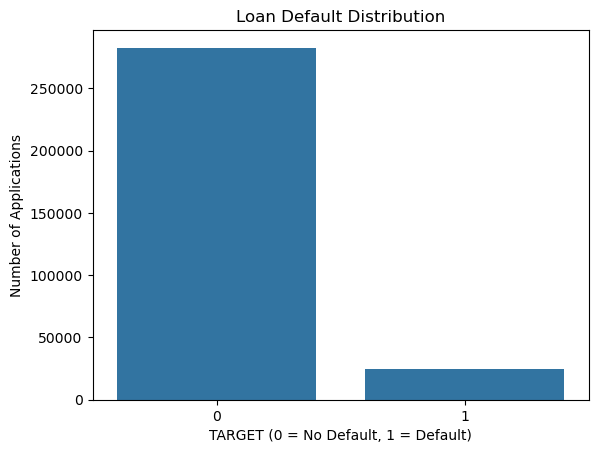

In [10]:
print(df["TARGET"].value_counts())
print("\nTarget percentage:")
print((df["TARGET"].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=df, x="TARGET")
plt.title("Loan Default Distribution")
plt.xlabel("TARGET (0 = No Default, 1 = Default)")
plt.ylabel("Number of Applications")
plt.show()

### EDA Finding – Class Imbalance

The target distribution shows whether defaults are less common than non-defaults. If the classes are imbalanced, accuracy alone may be misleading. Recall, precision, ROC-AUC, and average precision should also be considered.

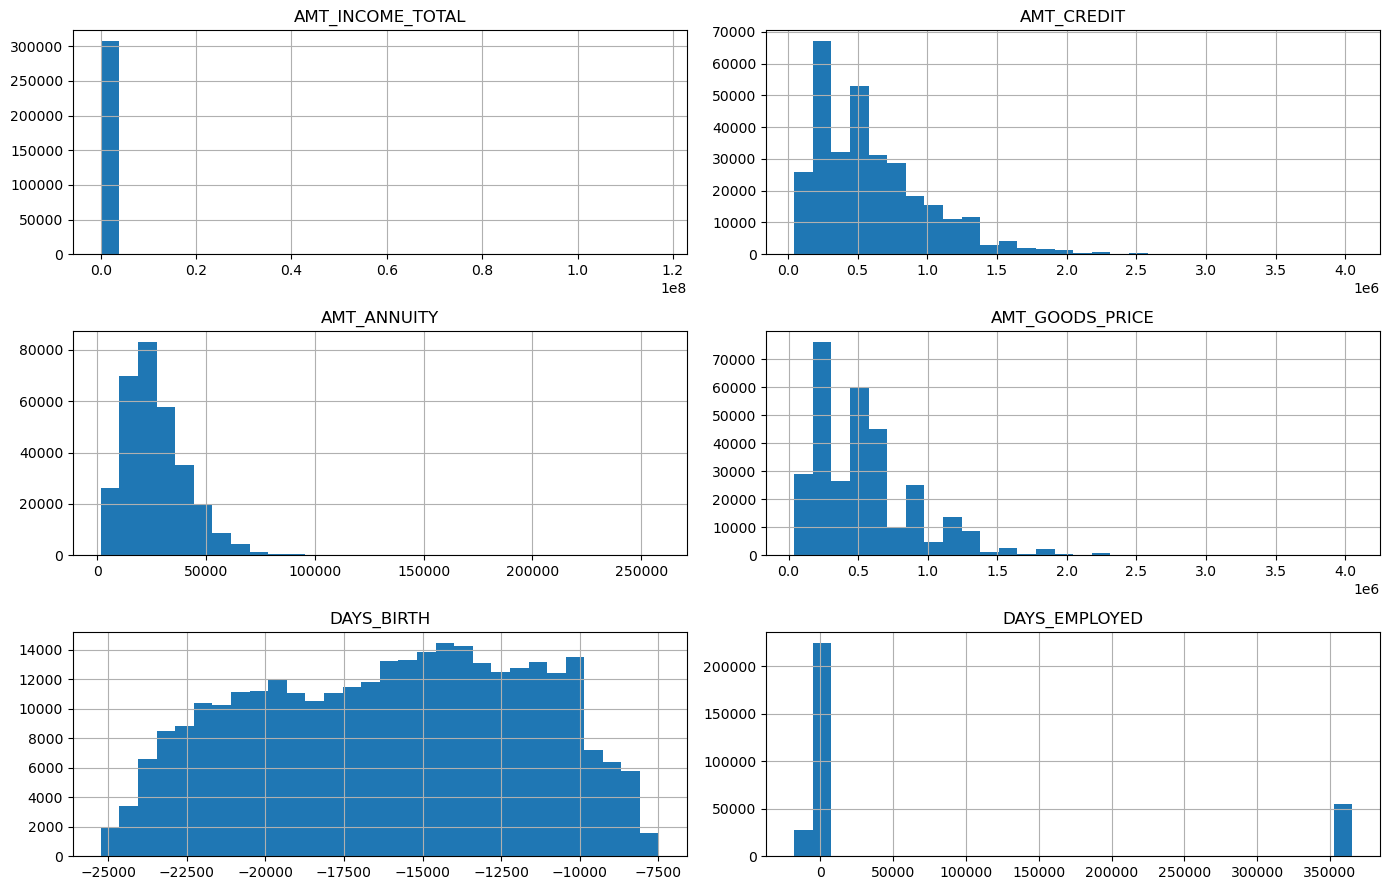

In [11]:
numeric_cols = df.select_dtypes(include=np.number).columns
selected_numeric = [
    col for col in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
                    "AMT_GOODS_PRICE", "DAYS_BIRTH", "DAYS_EMPLOYED"]
    if col in df.columns
]

df[selected_numeric].hist(figsize=(14, 9), bins=30)
plt.tight_layout()
plt.show()

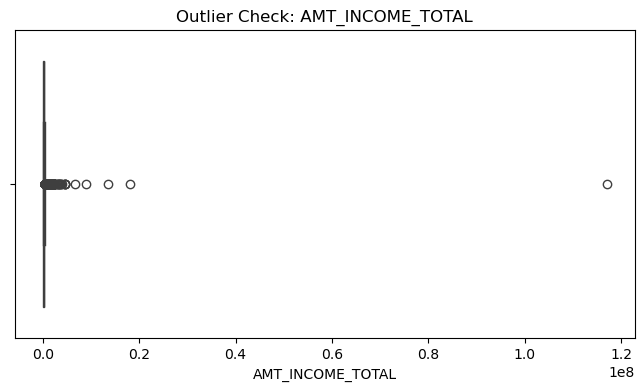

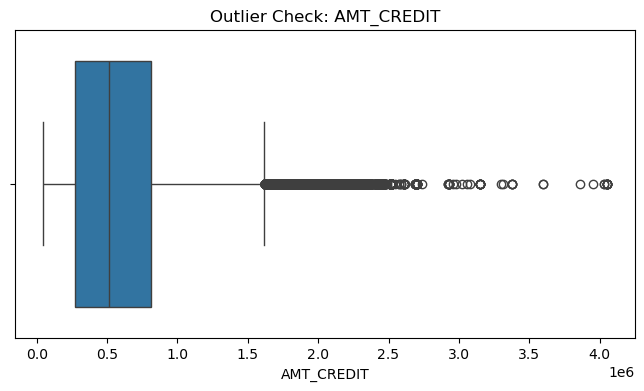

In [12]:
for col in ["AMT_INCOME_TOTAL", "AMT_CREDIT"]:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Check: {col}")
    plt.show()

### Outlier Interpretation

Boxplots help identify unusually high or low values. These observations are not automatically removed because they may represent genuine customers. Their effect should be evaluated carefully.

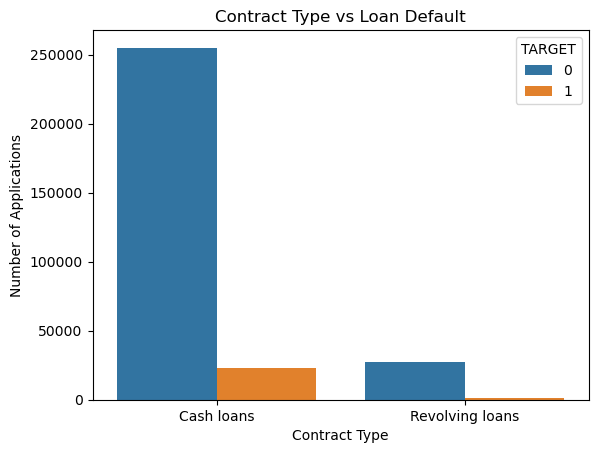

In [13]:
sns.countplot(data=df, x="NAME_CONTRACT_TYPE", hue="TARGET")
plt.title("Contract Type vs Loan Default")
plt.xlabel("Contract Type")
plt.ylabel("Number of Applications")
plt.show()

In [14]:
contract_default_rate = df.groupby("NAME_CONTRACT_TYPE")["TARGET"].mean() * 100
display(contract_default_rate.sort_values(ascending=False))

NAME_CONTRACT_TYPE
Cash loans         8.345913
Revolving loans    5.478329
Name: TARGET, dtype: float64

### Customer Segment Analysis
Default rates are calculated within customer groups, rather than comparing raw counts only. These are descriptive associations in the historical dataset; they do not establish causation and should not be used as stand-alone lending rules.

,Segment_Value,Customers,Default_Rate,Segment_Type
0,18-24,12233,12.29,Age group
1,25-34,72429,10.66,Age group
2,35-44,84261,8.41,Age group
3,45-54,70190,7.05,Age group
4,55+,68398,5.22,Age group
5,"(25649.999, 112500.0]",100578,8.39,Income quartile
6,"(112500.0, 147150.0]",53182,8.53,Income quartile
7,"(147150.0, 202500.0]",82213,8.40,Income quartile
8,"(202500.0, 117000000.0]",71538,6.91,Income quartile
9,Secondary / secondary special,218391,8.94,NAME_EDUCATION_TYPE


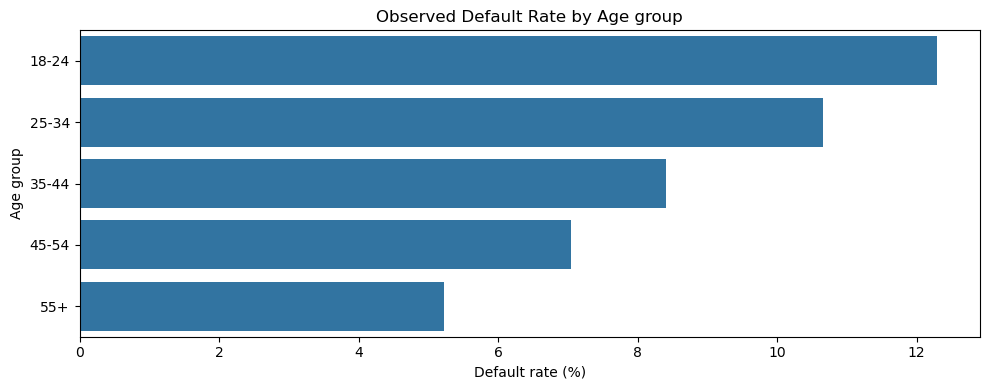

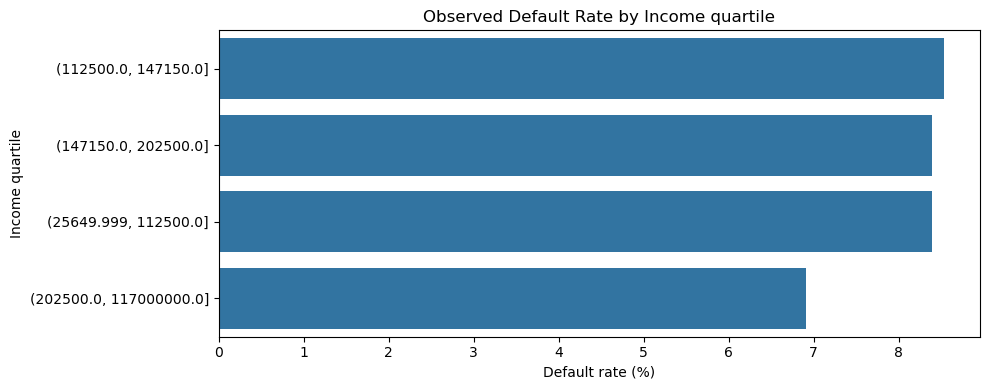

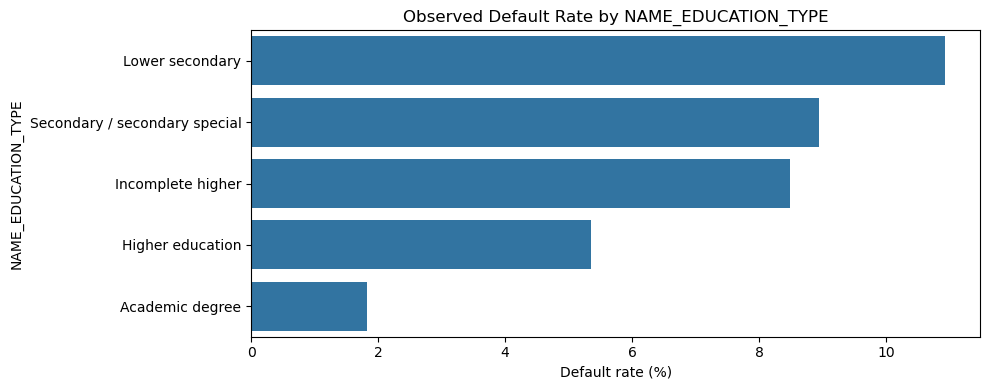

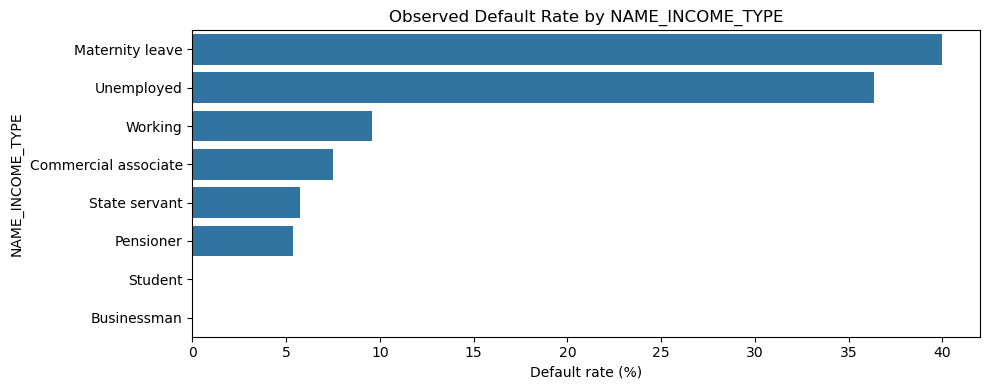

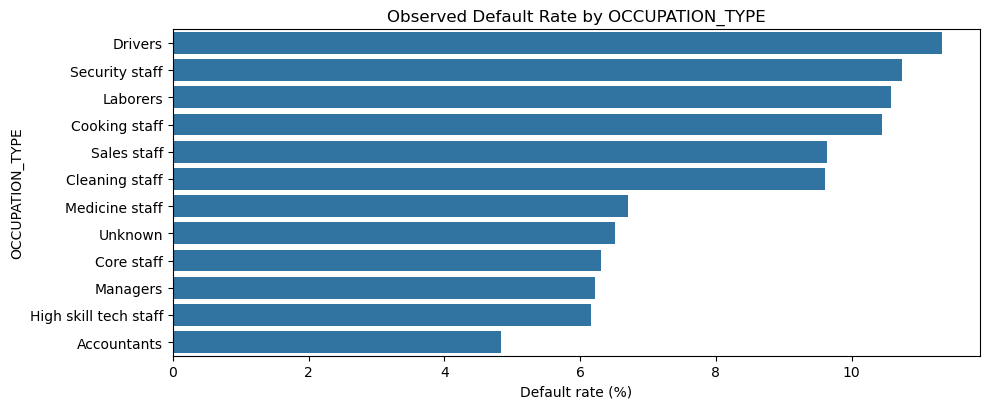

,Credit-to-income quartile,Customers,Default_Rate
0,"(0.00381, 2.019]",76948,7.46
1,"(2.019, 3.265]",76818,8.72
2,"(3.265, 5.16]",76868,8.74
3,"(5.16, 84.737]",76877,7.37


In [15]:
# Default rates across interpretable customer segments
# Use only columns that exist in the supplied dataset.
segment_frames = []

# Age groups
if "DAYS_BIRTH" in df.columns:
    age_years = (-df["DAYS_BIRTH"] / 365.25).clip(lower=0)
    age_group = pd.cut(
        age_years,
        bins=[0, 25, 35, 45, 55, 100],
        labels=["18-24", "25-34", "35-44", "45-54", "55+"],
        right=False
    )
    age_summary = pd.DataFrame({"Segment": age_group, "TARGET": df["TARGET"]})
    age_summary = age_summary.groupby("Segment", observed=False)["TARGET"].agg(
        Customers="count", Default_Rate="mean"
    ).reset_index()
    age_summary["Default_Rate"] *= 100
    age_summary["Segment_Type"] = "Age group"
    age_summary.rename(columns={"Segment": "Segment_Value"}, inplace=True)
    segment_frames.append(age_summary)

# Income groups: quantile-based bins reduce the impact of skewed income values.
if "AMT_INCOME_TOTAL" in df.columns:
    income = df["AMT_INCOME_TOTAL"].where(df["AMT_INCOME_TOTAL"] > 0)
    try:
        income_group = pd.qcut(income, q=4, duplicates="drop")
        income_summary = pd.DataFrame({"Segment": income_group, "TARGET": df["TARGET"]})
        income_summary = income_summary.groupby("Segment", observed=False)["TARGET"].agg(
            Customers="count", Default_Rate="mean"
        ).reset_index()
        income_summary["Default_Rate"] *= 100
        income_summary["Segment_Type"] = "Income quartile"
        income_summary.rename(columns={"Segment": "Segment_Value"}, inplace=True)
        segment_frames.append(income_summary)
    except ValueError:
        print("Income segmentation skipped because there were not enough distinct values.")

# Categorical segments
for col in ["NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE", "OCCUPATION_TYPE"]:
    if col in df.columns:
        temp = df[[col, "TARGET"]].copy()
        temp[col] = temp[col].fillna("Unknown")
        summary = temp.groupby(col, dropna=False)["TARGET"].agg(
            Customers="count", Default_Rate="mean"
        ).reset_index()
        summary["Default_Rate"] *= 100
        summary["Segment_Type"] = col
        summary.rename(columns={col: "Segment_Value"}, inplace=True)
        # Show the most populated categories for readability; retain all values in the source data.
        summary = summary.sort_values("Customers", ascending=False).head(12)
        segment_frames.append(summary)

if segment_frames:
    segment_summary = pd.concat(segment_frames, ignore_index=True)
    display(segment_summary.round(2))

    for segment_type in ["Age group", "Income quartile", "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE", "OCCUPATION_TYPE"]:
        plot_data = segment_summary[segment_summary["Segment_Type"] == segment_type].copy()
        if not plot_data.empty:
            plot_data = plot_data.sort_values("Default_Rate", ascending=False)
            plt.figure(figsize=(10, max(4, 0.35 * len(plot_data))))
            sns.barplot(data=plot_data, x="Default_Rate", y="Segment_Value")
            plt.title(f"Observed Default Rate by {segment_type}")
            plt.xlabel("Default rate (%)")
            plt.ylabel(segment_type)
            plt.tight_layout()
            plt.show()
else:
    print("No supported segment columns were found.")

# Credit burden: inspect credit-to-income ratio, a derived feature created below if available.
if "AMT_CREDIT" in df.columns and "AMT_INCOME_TOTAL" in df.columns:
    ratio = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"].replace(0, np.nan)
    ratio_group = pd.qcut(ratio.replace([np.inf, -np.inf], np.nan), q=4, duplicates="drop")
    ratio_summary = pd.DataFrame({"Credit-to-income quartile": ratio_group, "TARGET": df["TARGET"]})
    ratio_summary = ratio_summary.groupby("Credit-to-income quartile", observed=False)["TARGET"].agg(
        Customers="count", Default_Rate="mean"
    ).reset_index()
    ratio_summary["Default_Rate"] *= 100
    display(ratio_summary.round(2))


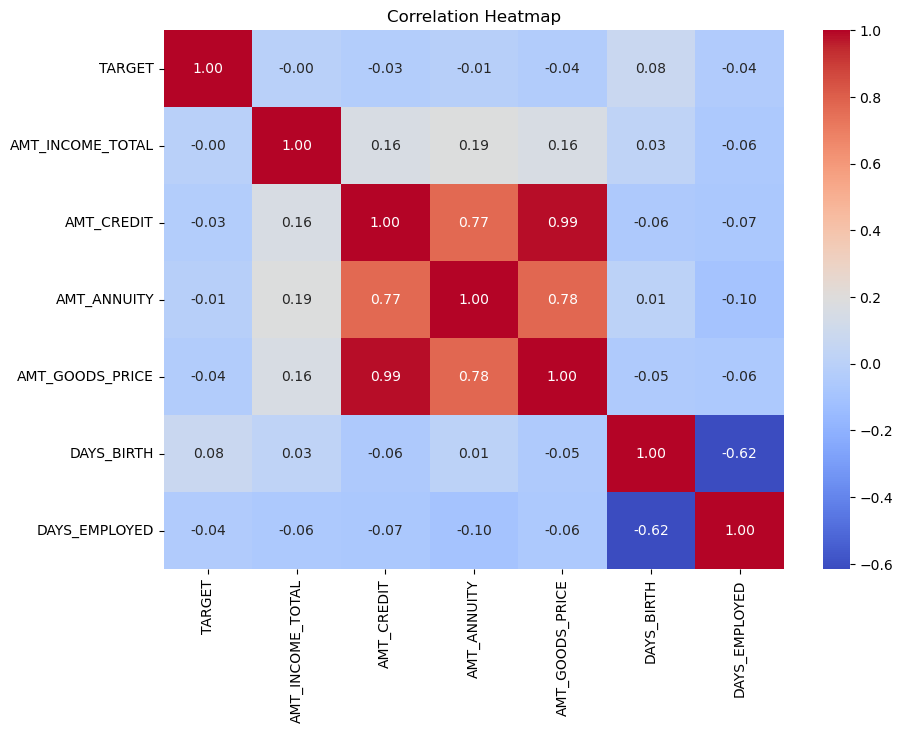

In [16]:
# Correlation heatmap for selected numerical columns
corr_cols = [
    col for col in ["TARGET", "AMT_INCOME_TOTAL", "AMT_CREDIT",
                    "AMT_ANNUITY", "AMT_GOODS_PRICE", "DAYS_BIRTH",
                    "DAYS_EMPLOYED"] if col in df.columns
]

plt.figure(figsize=(10, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

### EDA Summary

- Check the target distribution to understand class imbalance.
- Review missing values before model training.
- Numerical plots help identify skewed distributions and unusual values.
- Group default rates can reveal differences in the observed data, but do not prove causation.

### EDA Findings

- **Target distribution:** The dataset is imbalanced, with non-default customers forming the majority class. Accuracy alone is therefore insufficient for evaluating the models.
- **Age analysis:** Compare the default rates across age groups to identify whether default patterns vary with age.
- **Income and credit:** Examine income, credit amount, and annuity distributions to understand customer financial characteristics.
- **Missing values:** Missing data was handled using median imputation for numerical columns, fitted on the training data.
- **Loan type:** The observed default rate differs between cash loans and revolving loans. This is an association and does not establish that loan type causes default.

## 5. Data Preprocessing and Feature Engineering

The following steps create interpretable features, summarize historical records by customer, and prepare the model matrix. The ID column is used to merge historical data and then excluded from model inputs.

In [17]:

# Feature Engineering

df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)

df["AGE_YEARS"] = abs(df["DAYS_BIRTH"]) / 365.25
df["EMPLOYMENT_YEARS"] = abs(df["DAYS_EMPLOYED"]) / 365.25

df["CREDIT_INCOME_RATIO"] = (
    df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

df["ANNUITY_INCOME_RATIO"] = (
    df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

display(df[[
    "AGE_YEARS", "EMPLOYMENT_YEARS",
    "CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO"
]].head())


,AGE_YEARS,EMPLOYMENT_YEARS,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO
0,25.902806,1.744011,2.007889,0.121978
1,45.900068,3.252567,4.790750,0.132217
2,52.145106,0.616016,2.000000,0.100000
3,52.032854,8.320329,2.316167,0.219900
4,54.570842,8.317591,4.222222,0.179963


### Aggregate Historical Credit Data

Historical files may contain several rows for the same customer. We calculate summary statistics for each `SK_ID_CURR` and merge the summaries into the main application table.

In [18]:
bureau = pd.read_csv("bureau.csv")

bureau_features = bureau.groupby("SK_ID_CURR").agg(
    BUREAU_CREDIT_MEAN=("AMT_CREDIT_SUM", "mean"),
    BUREAU_CREDIT_MAX=("AMT_CREDIT_SUM", "max"),
    BUREAU_DEBT_MEAN=("AMT_CREDIT_SUM_DEBT", "mean"),
    BUREAU_DAYS_CREDIT_MEAN=("DAYS_CREDIT", "mean"),
    BUREAU_RECORD_COUNT=("SK_ID_BUREAU", "count")
).reset_index()

df = df.merge(bureau_features, on="SK_ID_CURR", how="left")
print("Shape after bureau aggregation:", df.shape)

Shape after bureau aggregation: (307511, 131)


In [19]:
previous = pd.read_csv("previous_application.csv")

previous_features = previous.groupby("SK_ID_CURR").agg(
    PREV_APPLICATION_MEAN=("AMT_APPLICATION", "mean"),
    PREV_CREDIT_MEAN=("AMT_CREDIT", "mean"),
    PREV_ANNUITY_MEAN=("AMT_ANNUITY", "mean"),
    PREV_APPLICATION_COUNT=("SK_ID_PREV", "count")
).reset_index()

df = df.merge(previous_features, on="SK_ID_CURR", how="left")
print("Shape after previous application aggregation:", df.shape)

Shape after previous application aggregation: (307511, 135)


In [20]:
pos = pd.read_csv("POS_CASH_balance.csv")

pos_features = pos.groupby("SK_ID_CURR").agg(
    POS_MONTHS_BALANCE_MIN=("MONTHS_BALANCE", "min"),
    POS_RECORD_COUNT=("SK_ID_PREV", "count")
).reset_index()

df = df.merge(pos_features, on="SK_ID_CURR", how="left")
print("Shape after POS aggregation:", df.shape)

Shape after POS aggregation: (307511, 137)


In [21]:
credit_card = pd.read_csv("credit_card_balance.csv")

card_features = credit_card.groupby("SK_ID_CURR").agg(
    CARD_BALANCE_MEAN=("AMT_BALANCE", "mean"),
    CARD_LIMIT_MEAN=("AMT_CREDIT_LIMIT_ACTUAL", "mean"),
    CARD_DRAWINGS_MEAN=("AMT_DRAWINGS_CURRENT", "mean"),
    CARD_RECORD_COUNT=("SK_ID_PREV", "count")
).reset_index()

df = df.merge(card_features, on="SK_ID_CURR", how="left")
print("Shape after credit card aggregation:", df.shape)

Shape after credit card aggregation: (307511, 141)


In [22]:
installments = pd.read_csv("installments_payments.csv")

installment_features = installments.groupby("SK_ID_CURR").agg(
    INST_PAYMENT_MEAN=("AMT_PAYMENT", "mean"),
    INST_AMOUNT_MEAN=("AMT_INSTALMENT", "mean"),
    INST_RECORD_COUNT=("SK_ID_PREV", "count")
).reset_index()

df = df.merge(installment_features, on="SK_ID_CURR", how="left")
print("Shape after installment aggregation:", df.shape)

Shape after installment aggregation: (307511, 144)


In [23]:
# Summarize monthly bureau balance by customer using the bureau ID mapping
bureau_balance = pd.read_csv("bureau_balance.csv")
bureau_ids = bureau[["SK_ID_BUREAU", "SK_ID_CURR"]].drop_duplicates()

balance_customer = bureau_balance.merge(
    bureau_ids, on="SK_ID_BUREAU", how="inner"
)

balance_features = balance_customer.groupby("SK_ID_CURR").agg(
    BB_MONTHS_MEAN=("MONTHS_BALANCE", "mean"),
    BB_RECORD_COUNT=("MONTHS_BALANCE", "count")
).reset_index()

df = df.merge(balance_features, on="SK_ID_CURR", how="left")
print("Shape after bureau balance aggregation:", df.shape)

Shape after bureau balance aggregation: (307511, 146)


### Preprocessing Decisions
- Historical tables are aggregated to one row per `SK_ID_CURR` before merging, preventing row multiplication in the main application table.
- `SK_ID_CURR` is retained for joins but excluded from model inputs because it is an identifier, not a meaningful predictive measurement.
- Infinite derived ratios are converted to missing values.
- Numerical missing values are imputed with the training-set median; categorical missing values use the most frequent training value, followed by one-hot encoding in the pipeline-based models.
- Random undersampling is applied only to training folds/data. Validation and test sets keep the original class distribution.
- The test set is held out until final evaluation. Threshold choice is made on validation data, not on test results.

In [24]:

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Separate features and target
X = df.drop(columns=["TARGET", "SK_ID_CURR"])
y = df["TARGET"].astype(int)

# Replace infinite values before splitting
X = X.replace([np.inf, -np.inf], np.nan)

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)


Feature matrix: (307511, 144)
Target vector: (307511,)


In [25]:
# Split data into training and test sets
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Split training data into training and validation sets
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

# Save raw copies for pipeline-based models
X_train_raw = X_train_sub.copy()
X_val_raw = X_val.copy()
X_test_raw = X_test.copy()

# Replace infinite values with NaN
X_train_raw = X_train_raw.replace([np.inf, -np.inf], np.nan)
X_val_raw = X_val_raw.replace([np.inf, -np.inf], np.nan)
X_test_raw = X_test_raw.replace([np.inf, -np.inf], np.nan)

# Identify numerical and categorical columns
numeric_features = X_train_raw.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train_raw.select_dtypes(
    exclude=np.number
).columns.tolist()

# Create preprocessing pipeline for raw data
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    drop="first"
                ))
            ]),
            categorical_features
        )
    ],
    remainder="drop"
)

# Replace infinite values in data used by baseline models
X_train_sub = X_train_sub.replace([np.inf, -np.inf], np.nan)
X_val = X_val.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# Apply one-hot encoding
X_train_sub = pd.get_dummies(
    X_train_sub,
    drop_first=True,
    dummy_na=True,
    dtype=int
)

X_val = pd.get_dummies(
    X_val,
    drop_first=True,
    dummy_na=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    drop_first=True,
    dummy_na=True,
    dtype=int
)

# Align validation and test columns with training columns
X_val = X_val.reindex(
    columns=X_train_sub.columns,
    fill_value=0
)

X_test = X_test.reindex(
    columns=X_train_sub.columns,
    fill_value=0
)

# Calculate medians using training data only
train_medians = X_train_sub.median()

# Fill missing values
X_train = X_train_sub.fillna(train_medians)
X_val = X_val.fillna(train_medians)
X_test = X_test.fillna(train_medians)

# Prepare training target
y_train = y_train_sub.copy()

# Display dataset information
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nMissing values after preprocessing:")
print("Training:", X_train.isnull().sum().sum())
print("Validation:", X_val.isnull().sum().sum())
print("Test:", X_test.isnull().sum().sum())

Training shape: (196806, 268)
Validation shape: (49202, 268)
Test shape: (61503, 268)
Numerical features: 128
Categorical features: 16

Missing values after preprocessing:
Training: 0
Validation: 0
Test: 0


## 6. Handling Class Imbalance

The target may contain many more non-defaults than defaults. Random undersampling reduces the majority class in the training data. The test data remains unchanged so evaluation reflects the original class distribution.

**Limitation:** Undersampling discards some non-default examples and can remove useful information.

In [26]:
print("Training class distribution before balancing:")
print(y_train.value_counts())

rus = RandomUnderSampler(random_state=42)
X_train_balanced, y_train_balanced = rus.fit_resample(X_train, y_train)

print("\nTraining class distribution after balancing:")
print(y_train_balanced.value_counts())

Training class distribution before balancing:
TARGET
0    180918
1     15888
Name: count, dtype: int64

Training class distribution after balancing:
TARGET
0    15888
1    15888
Name: count, dtype: int64


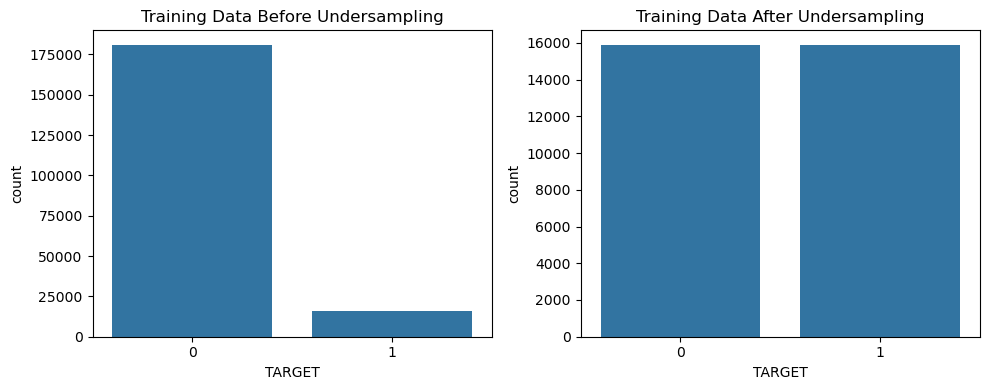

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Training Data Before Undersampling")
axes[0].set_xlabel("TARGET")

sns.countplot(x=y_train_balanced, ax=axes[1])
axes[1].set_title("Training Data After Undersampling")
axes[1].set_xlabel("TARGET")

plt.tight_layout()
plt.show()

**Model Evaluation Function**

The evaluation function trains the model on the training data and evaluates its performance on the validation set. It calculates Accuracy, Precision, Recall, F1-score, ROC-AUC, and Average Precision. The validation results are used to compare baseline models and select the most promising model before final testing.

In [28]:

def evaluate_model(model_name, model, Xtr, ytr, Xval, yval):
    model.fit(Xtr, ytr)

    predictions = model.predict(Xval)
    probabilities = model.predict_proba(Xval)[:, 1]

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(yval, predictions),
        "Precision": precision_score(
            yval, predictions, zero_division=0
        ),
        "Recall": recall_score(
            yval, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            yval, predictions, zero_division=0
        ),
        "ROC AUC": roc_auc_score(yval, probabilities),
        "Average Precision": average_precision_score(
            yval, probabilities
        )
    }

    print("=" * 50)
    print(model_name)
    print("=" * 50)
    print(classification_report(
        yval, predictions, zero_division=0
    ))

    return model, predictions, probabilities, metrics


## 7. Model Building

**Baseline Model Evaluation**

Five baseline classification models are compared using the validation dataset. The same evaluation metrics are used for each model to ensure a consistent comparison. The test dataset is kept separate for final evaluation after model selection and tuning.


### Model 1: Logistic Regression

In [29]:
model_1 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])


model_1, pred_1, prob_1, result_1 = evaluate_model(
    "Logistic Regression", model_1,
    X_train_balanced, y_train_balanced, X_val, y_val
)



Logistic Regression
              precision    recall  f1-score   support

           0       0.96      0.69      0.80     45230
           1       0.16      0.69      0.26      3972

    accuracy                           0.69     49202
   macro avg       0.56      0.69      0.53     49202
weighted avg       0.90      0.69      0.76     49202



### Model 2: Decision Tree

In [30]:
model_2 = DecisionTreeClassifier(
    max_depth=8, random_state=42
)

model_2, pred_2, prob_2, result_2 = evaluate_model(
    "Decision Tree", model_2,
    X_train_balanced, y_train_balanced,X_val, y_val
)

Decision Tree
              precision    recall  f1-score   support

           0       0.96      0.63      0.76     45230
           1       0.14      0.67      0.23      3972

    accuracy                           0.63     49202
   macro avg       0.55      0.65      0.49     49202
weighted avg       0.89      0.63      0.72     49202



### Model 3: Random Forest

In [31]:
model_3 = RandomForestClassifier(
    n_estimators=100, max_depth=12,
    random_state=42, n_jobs=-1
)

model_3, pred_3, prob_3, result_3 = evaluate_model(
    "Random Forest", model_3,
    X_train_balanced, y_train_balanced,X_val, y_val
)

Random Forest
              precision    recall  f1-score   support

           0       0.96      0.68      0.80     45230
           1       0.16      0.69      0.26      3972

    accuracy                           0.68     49202
   macro avg       0.56      0.68      0.53     49202
weighted avg       0.90      0.68      0.75     49202



### Model 4: XGBoost

In [32]:
model_4 = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

model_4, pred_4, prob_4, result_4 = evaluate_model(
    "XGBoost", model_4,
    X_train_balanced, y_train_balanced, X_val, y_val
)

XGBoost
              precision    recall  f1-score   support

           0       0.96      0.69      0.80     45230
           1       0.16      0.69      0.26      3972

    accuracy                           0.69     49202
   macro avg       0.56      0.69      0.53     49202
weighted avg       0.90      0.69      0.76     49202



### Model 5: Gradient Boosting

In [33]:
model_5 = GradientBoostingClassifier(
    n_estimators=50, learning_rate=0.1,
    max_depth=3, random_state=42
)

model_5, pred_5, prob_5, result_5 = evaluate_model(
    "Gradient Boosting", model_5,
    X_train_balanced, y_train_balanced,X_val, y_val
)

Gradient Boosting
              precision    recall  f1-score   support

           0       0.96      0.68      0.80     45230
           1       0.16      0.68      0.26      3972

    accuracy                           0.68     49202
   macro avg       0.56      0.68      0.53     49202
weighted avg       0.90      0.68      0.75     49202



## 8. Model Comparison Report
All baseline models are compared using accuracy, precision, recall, F1-score, ROC-AUC, and average precision. ROC-AUC measures ranking ability, while average precision is especially useful for understanding precision-recall behavior when the positive class is rare.

In [34]:
models = {
    "Logistic Regression": model_1,
    "Decision Tree": model_2,
    "Random Forest": model_3,
    "XGBoost": model_4,
    "Gradient Boosting": model_5
}

model_probabilities = {
    "Logistic Regression": prob_1,
    "Decision Tree": prob_2,
    "Random Forest": prob_3,
    "XGBoost": prob_4,
    "Gradient Boosting": prob_5
}

results_df = pd.DataFrame([
    result_1, result_2, result_3, result_4, result_5
]).sort_values("ROC AUC", ascending=False).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Average Precision
0,XGBoost,0.6904,0.1635,0.6886,0.2642,0.7575,0.2392
1,Logistic Regression,0.6895,0.1627,0.6866,0.2631,0.7530,0.2205
2,Gradient Boosting,0.6821,0.1585,0.6815,0.2571,0.7450,0.2214
3,Random Forest,0.6801,0.1583,0.6866,0.2573,0.7413,0.2105
4,Decision Tree,0.6337,0.1380,0.6740,0.2290,0.6968,0.1592


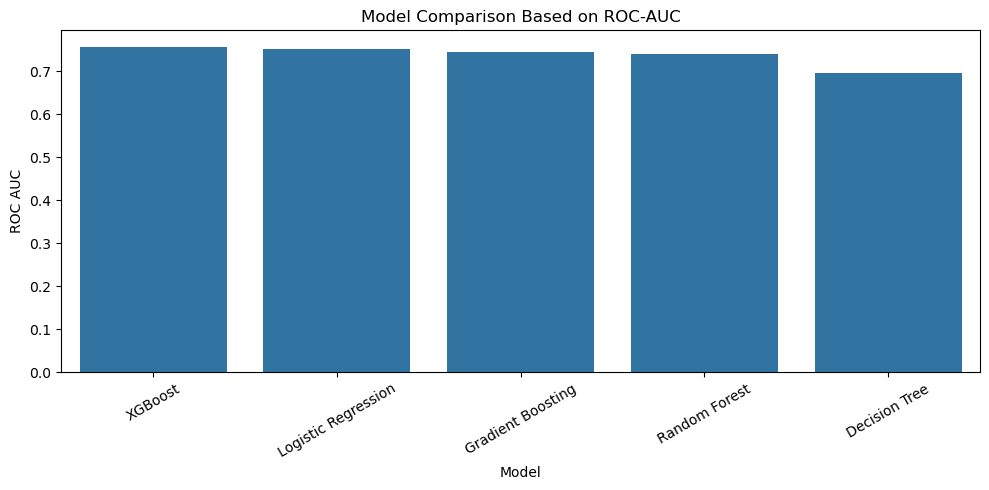

In [35]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="ROC AUC")
plt.xticks(rotation=30)
plt.title("Model Comparison Based on ROC-AUC")
plt.tight_layout()
plt.show()

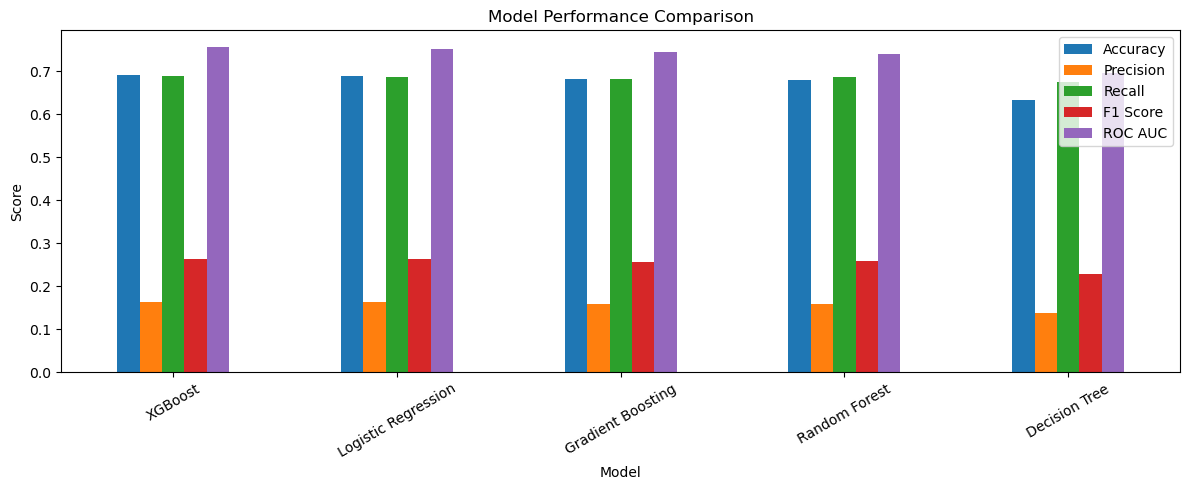

In [36]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
].plot(kind="bar", figsize=(12, 5))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 9. Best Baseline Model
The baseline model with the highest validation ROC-AUC is selected for further consideration. Average Precision is also reviewed because the positive (default) class is relatively uncommon. The final production candidate must be chosen using validation results and business costs; test data is reserved for a final, one-time comparison.

In [37]:
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]

print("Best baseline model based on ROC-AUC:", best_name)
display(results_df.iloc[[0]].round(4))

Best baseline model based on ROC-AUC: XGBoost


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Average Precision
0,XGBoost,0.6904,0.1635,0.6886,0.2642,0.7575,0.2392


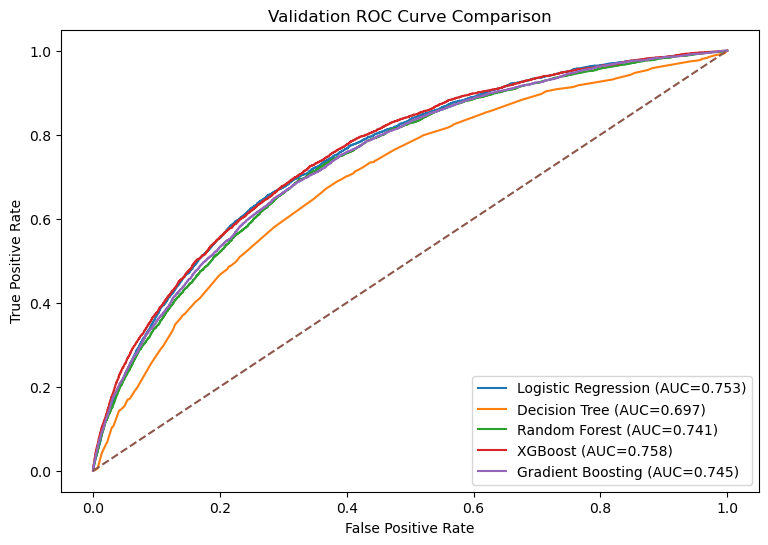

In [38]:
plt.figure(figsize=(9, 6))

for name, probabilities in model_probabilities.items():
    fpr, tpr, _ = roc_curve(y_val, probabilities)
    auc_score = roc_auc_score(y_val, probabilities)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC={auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curve Comparison")
plt.legend()
plt.show()


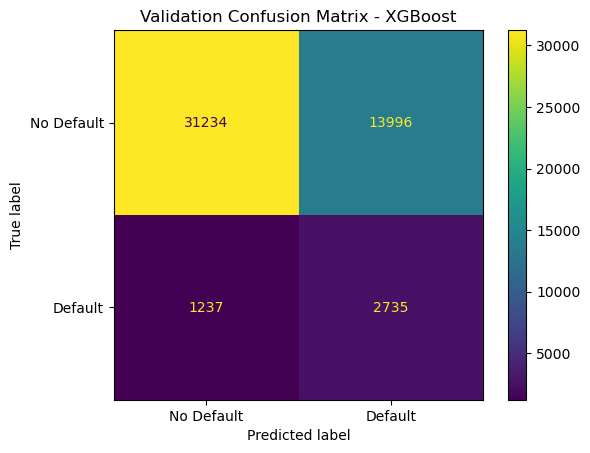

In [39]:

best_prob = model_probabilities[best_name]
best_pred = (best_prob >= 0.50).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_val, best_pred,
    display_labels=["No Default", "Default"]
)

plt.title(f"Validation Confusion Matrix - {best_name}")
plt.show()

## 10. Cross-Validation
A single train-test split gives one estimate of performance. Stratified 5-fold cross-validation estimates performance across multiple splits while preserving the target proportions.

Undersampling is applied inside each training fold. The validation fold is not resampled, which helps avoid leakage and keeps validation evaluation closer to the original distribution.

In [40]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_pipeline = ImbPipeline([
    ("preprocess", preprocessor),
    ("sampler", RandomUnderSampler(random_state=42)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=1
    ))
])

cv_scores = cross_val_score(
    cv_pipeline,
    X_train_raw,
    y_train_sub,
    cv=cv,
    scoring="roc_auc",
    n_jobs=1,
    pre_dispatch=1
)

print("5-Fold ROC-AUC scores:", np.round(cv_scores, 4))
print("Mean ROC-AUC:", round(cv_scores.mean(), 4))
print("Standard deviation:", round(cv_scores.std(), 4))

5-Fold ROC-AUC scores: [0.7346 0.7397 0.7452 0.7414 0.7438]
Mean ROC-AUC: 0.7409
Standard deviation: 0.0037


## 11. Hyperparameter Tuning
Hyperparameter tuning searches for a better set of model settings. The example below tunes a Random Forest with randomized search. Because the full Home Credit dataset is large, this step can be computationally expensive; reduce n_iter or use a training sample if needed.

In [41]:
# Validation split was already created in Cell 35

print("Model development data:", X_train_sub.shape)
print("Validation data:", X_val.shape)



Model development data: (196806, 268)
Validation data: (49202, 268)


In [42]:

rf_pipeline = ImbPipeline([
    ("preprocess", preprocessor),
    ("sampler", RandomUnderSampler(random_state=42)),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

rf_param_dist = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [8, 12, 16],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_dist,
    n_iter=5,
    cv=3,
    scoring="roc_auc",
    n_jobs=1,
    random_state=42,
    verbose=1,
    pre_dispatch=1
)
# Train using raw development data
rf_search.fit(X_train_raw, y_train_sub)

print("Best parameters:")
print(rf_search.best_params_)

print(
    "Best cross-validation ROC-AUC:",
    round(rf_search.best_score_, 4)
)


Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 16}
Best cross-validation ROC-AUC: 0.734


## 12. Threshold Tuning
A probability threshold of 0.50 is the default. A lower threshold usually increases recall and may reduce precision; a higher threshold usually increases precision and may reduce recall.

The threshold is selected using a validation split from the training data. The final test set remains untouched until final evaluation.

In [43]:
# Threshold tuning for the selected baseline candidate (XGBoost)
# The threshold is chosen on validation data only. It is not optimized on the test set.
final_model_name = "XGBoost"
final_xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

final_xgb_model.fit(X_train_balanced, y_train_balanced)
val_prob = final_xgb_model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.05)
threshold_rows = []
for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1 Score": f1_score(y_val, val_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(3))

# Select the threshold that maximizes validation F1-score; the business may later
# choose a different threshold after documenting the cost of false positives/negatives.
best_threshold = float(threshold_df.loc[threshold_df["F1 Score"].idxmax(), "Threshold"])
print("Selected XGBoost threshold based on validation F1-score:", round(best_threshold, 2))

# Tune a separate validation threshold for the Random Forest benchmark.
# This keeps its decision metrics from borrowing the XGBoost threshold.
tuned_rf_pipeline = rf_search.best_estimator_
rf_val_prob = tuned_rf_pipeline.predict_proba(X_val_raw)[:, 1]
rf_threshold_rows = []
for threshold in thresholds:
    rf_val_pred = (rf_val_prob >= threshold).astype(int)
    rf_threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, rf_val_pred, zero_division=0),
        "Recall": recall_score(y_val, rf_val_pred, zero_division=0),
        "F1 Score": f1_score(y_val, rf_val_pred, zero_division=0)
    })
rf_threshold_df = pd.DataFrame(rf_threshold_rows)
rf_best_threshold = float(rf_threshold_df.loc[rf_threshold_df["F1 Score"].idxmax(), "Threshold"])
print("Selected Random Forest benchmark threshold based on validation F1-score:", round(rf_best_threshold, 2))


,Threshold,Precision,Recall,F1 Score
0,0.10,0.082,0.999,0.151
1,0.15,0.085,0.993,0.157
2,0.20,0.091,0.977,0.167
3,0.25,0.100,0.951,0.181
4,0.30,0.110,0.913,0.197
5,0.35,0.122,0.874,0.215
6,0.40,0.135,0.824,0.232
7,0.45,0.149,0.762,0.249
8,0.50,0.163,0.689,0.264
9,0.55,0.181,0.611,0.279


Selected XGBoost threshold based on validation F1-score: 0.65
Selected Random Forest benchmark threshold based on validation F1-score: 0.6


FINAL XGBOOST TEST RESULTS
Selected threshold: 0.65

Classification Report:
              precision    recall  f1-score   support

  No Default       0.95      0.87      0.91     56538
     Default       0.24      0.45      0.31      4965

    accuracy                           0.84     61503
   macro avg       0.59      0.66      0.61     61503
weighted avg       0.89      0.84      0.86     61503



,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,XGBoost,0.65,0.8385,0.2372,0.4514,0.311,0.7609,0.2512


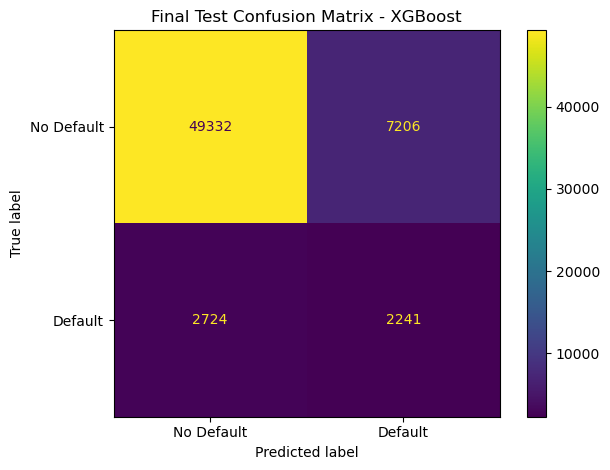

Tuned Random Forest benchmark metrics (same test set):


,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Tuned Random Forest,0.6,0.8545,0.2353,0.3567,0.2836,0.7391,0.2122


In [44]:
# Final evaluation on the untouched test set
# XGBoost is the selected baseline candidate based on the recorded validation comparison.
# The tuned Random Forest is evaluated as a benchmark using the same held-out test set.

final_xgb_model.fit(X_train_balanced, y_train_balanced)
test_prob = final_xgb_model.predict_proba(X_test)[:, 1]
final_test_pred = (test_prob >= best_threshold).astype(int)

print("FINAL XGBOOST TEST RESULTS")
print("Selected threshold:", round(best_threshold, 2))
print("\nClassification Report:")
print(classification_report(
    y_test, final_test_pred,
    target_names=["No Default", "Default"],
    zero_division=0
))

final_test_metrics = {
    "Model": "XGBoost",
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, final_test_pred),
    "Precision": precision_score(y_test, final_test_pred, zero_division=0),
    "Recall": recall_score(y_test, final_test_pred, zero_division=0),
    "F1 Score": f1_score(y_test, final_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_prob),
    "Average Precision": average_precision_score(y_test, test_prob)
}
display(pd.DataFrame([final_test_metrics]).round(4))

ConfusionMatrixDisplay.from_predictions(
    y_test, final_test_pred,
    display_labels=["No Default", "Default"]
)
plt.title("Final Test Confusion Matrix - XGBoost")
plt.tight_layout()
plt.show()

# Keep the tuned Random Forest test probabilities as a comparison only.
final_rf_pipeline = rf_search.best_estimator_
final_rf_pipeline.fit(X_train_raw, y_train_sub)
rf_test_prob = final_rf_pipeline.predict_proba(X_test_raw)[:, 1]
rf_test_pred = (rf_test_prob >= rf_best_threshold).astype(int)
rf_test_metrics = {
    "Model": "Tuned Random Forest",
    "Threshold": rf_best_threshold,
    "Accuracy": accuracy_score(y_test, rf_test_pred),
    "Precision": precision_score(y_test, rf_test_pred, zero_division=0),
    "Recall": recall_score(y_test, rf_test_pred, zero_division=0),
    "F1 Score": f1_score(y_test, rf_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, rf_test_prob),
    "Average Precision": average_precision_score(y_test, rf_test_prob)
}
print("Tuned Random Forest benchmark metrics (same test set):")
display(pd.DataFrame([rf_test_metrics]).round(4))

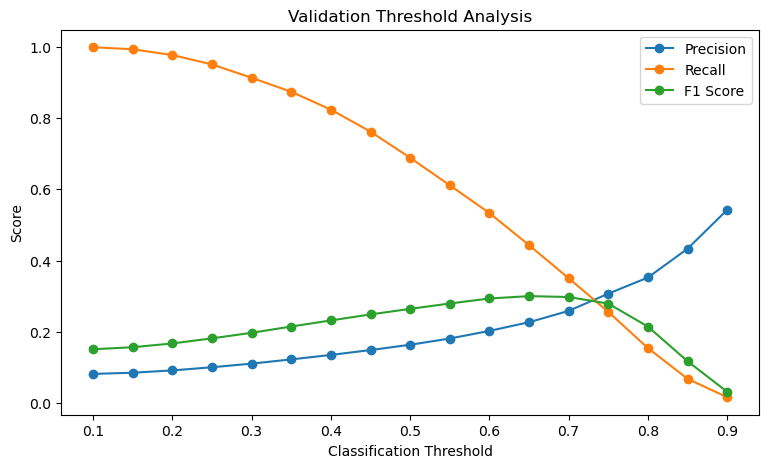

In [45]:
plt.figure(figsize=(9, 5))

plt.plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="o", label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F1 Score"], marker="o", label="F1 Score")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Validation Threshold Analysis")
plt.legend()
plt.show()

## 13. Feature Importance / Interpretability
Random Forest feature importance shows which features were most useful for tree splits. It does not show causation, and importance values can be affected by correlated features and feature types.

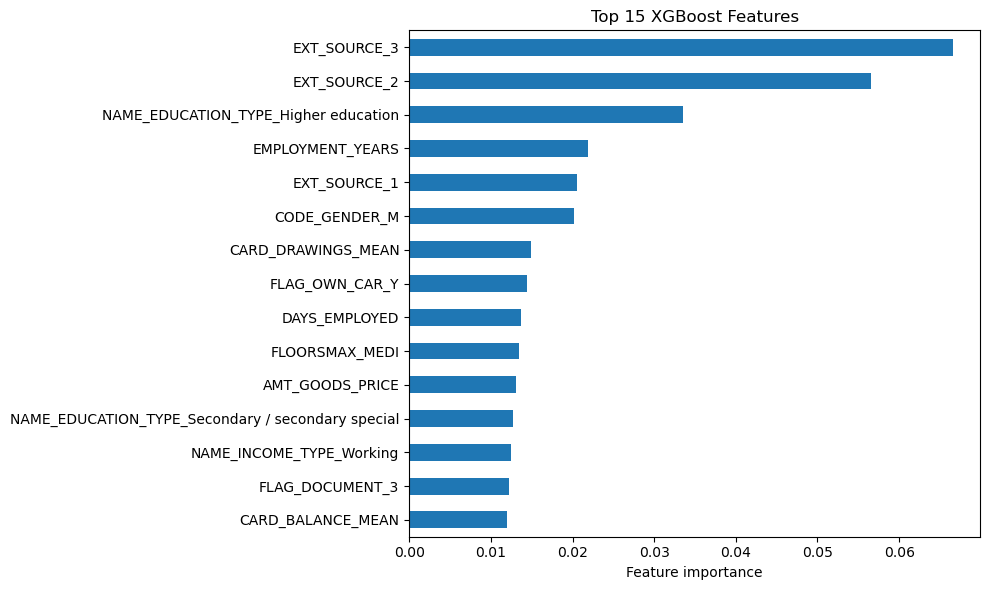

,Importance
EXT_SOURCE_3,0.066576
EXT_SOURCE_2,0.056519
NAME_EDUCATION_TYPE_Higher education,0.033514
EMPLOYMENT_YEARS,0.021914
EXT_SOURCE_1,0.020567
CODE_GENDER_M,0.020208
CARD_DRAWINGS_MEAN,0.014856
FLAG_OWN_CAR_Y,0.014476
DAYS_EMPLOYED,0.013720
FLOORSMAX_MEDI,0.013485


In [46]:
# Feature importance for the selected XGBoost model
# This measures contribution to model splits, not causation.
feature_importance = pd.Series(
    final_xgb_model.feature_importances_,
    index=X_train_balanced.columns
).sort_values(ascending=False)

top_features = feature_importance.head(15)
plt.figure(figsize=(10, 6))
top_features.sort_values().plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("Top 15 XGBoost Features")
plt.tight_layout()
plt.show()
display(top_features.to_frame("Importance"))

## 14. Customer Risk Scores
The model's probability estimates can be used to group customers into illustrative risk segments. The cutoffs below are examples only and must not be treated as approved lending rules.

A higher score means the model estimates a higher probability of default, subject to calibration and validation.

In [47]:
risk_df = pd.DataFrame({
    "Actual_Default": y_test.to_numpy(),
    "Default_Risk_Score": test_prob
})

risk_df["Risk_Segment"] = pd.cut(
    risk_df["Default_Risk_Score"],
    bins=[-0.001, 0.30, 0.60, 1.0],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

display(risk_df.head(10))

,Actual_Default,Default_Risk_Score,Risk_Segment
0,0,0.270908,Low Risk
1,0,0.318419,Medium Risk
2,0,0.712439,High Risk
3,0,0.373534,Medium Risk
4,0,0.554267,Medium Risk
5,0,0.625005,High Risk
6,0,0.187165,Low Risk
7,0,0.123701,Low Risk
8,0,0.846234,High Risk
9,1,0.446388,Medium Risk


In [48]:
risk_summary = risk_df.groupby("Risk_Segment", observed=False).agg(
    Customers=("Actual_Default", "count"),
    Actual_Default_Rate=("Actual_Default", "mean"),
    Average_Risk_Score=("Default_Risk_Score", "mean")
)

risk_summary["Actual_Default_Rate"] *= 100
display(risk_summary.round(2))

,Customers,Actual_Default_Rate,Average_Risk_Score
Risk_Segment,,,
Low Risk,20276,2.18,0.21
Medium Risk,28366,6.49,0.44
High Risk,12861,20.85,0.71


### Risk Segmentation Interpretation
The score bands below are illustrative reporting groups, not approved lending cutoffs. Compare the actual default rate and number of customers in each band. If the rates do not rise from low to high risk, investigate model calibration and segment stability before using these groups. Segment labels alone should not be interpreted as loan-approval decisions.

# 15. Challenges Faced and Techniques Used

### Challenge 1 – Class imbalance
**Problem:** Default cases are a minority of applications, so a model can achieve high accuracy while missing defaults.

**Technique:** Random undersampling is used on training data only. Validation and test distributions remain unchanged. Precision, recall, F1-score, ROC-AUC, and Average Precision are reported. Undersampling can discard information and can change the probability distribution, so the scores and threshold require further validation.

### Challenge 2 – Missing values
**Problem:** Application and historical data contain missing values, sometimes because a field does not apply or was not recorded.

**Technique:** Numerical features are imputed with the median and categorical features with the most frequent category inside the preprocessing pipeline. Missingness itself may carry information, so future work can test missing-indicator features and document field-specific reasons for missingness.

### Challenge 3 – Multiple historical records per customer
**Problem:** Bureau, balance, and repayment tables contain multiple records for one customer and can multiply rows if merged directly.

**Technique:** Aggregate each history table by `SK_ID_CURR` before merging. This keeps one application-level row per customer. These summary features are useful but may lose sequence and timing information.

### Challenge 4 – Large data and memory use
**Problem:** Joining several large CSV files and one-hot encoding categorical variables can consume substantial memory and runtime.

**Technique:** Use customer-level groupby summaries, keep only relevant aggregate columns, and limit hyperparameter-search iterations during development. For a production pipeline, consider efficient dtypes, reproducible feature generation, and resource monitoring.

### Challenge 5 – Outliers and special-coded values
**Problem:** Some numeric values are highly skewed, and `DAYS_EMPLOYED = 365243` is a special placeholder rather than a realistic duration.

**Technique:** Convert that placeholder to missing and derive age/employment duration features. Extreme financial values are inspected rather than automatically deleted because they may represent genuine applications. Validate extreme records before making any removal decision.

### Challenge 6 – Leakage and fair evaluation
**Problem:** Preprocessing, sampling, or threshold selection performed using validation/test data can overstate performance.

**Technique:** Fit imputers/encoders inside pipelines for the tuned model, sample only training data, select thresholds on validation data, and reserve the test set for final evaluation. Historical features should be checked to ensure they would have been available at the application decision time.

### Challenge 7 – Choosing a useful model
**Problem:** There is no single metric that captures the cost of all incorrect predictions.

**Technique:** Compare several models and report ROC-AUC, Average Precision, precision, recall, F1-score, and confusion matrices. The final threshold should reflect documented business costs and should be revalidated with calibration, fairness, and temporal testing.

## Business Implications
The model can support risk assessment by prioritizing applications for additional review.
### False Positive
The model predicts default for a customer who does not actually default.

**Potential impact:** A reliable customer may face unnecessary review or an unfair lending outcome.
### False Negative
The model predicts no default for a customer who actually defaults.

**Potential impact:** The bank may underestimate credit risk.
### Practical Decision
The threshold should reflect the bank's risk appetite and the relative costs of false positives and false negatives. Model predictions should not be the sole basis for accepting or rejecting a loan application.


## Business Recommendations

1. **Prioritize applications for review:** Use model scores as
   one input to identify applications that may need additional
   credit-risk assessment.

2. **Consider the cost of missed defaults:** Evaluate recall
   alongside precision because missing a high-risk application
   may create financial losses.

3. **Avoid relying on accuracy alone:** Compare ROC-AUC,
   average precision, precision, recall, and F1-score to assess
   model performance on the minority default class.

4. **Choose thresholds based on business needs:** Select the
   decision threshold using validation data and documented
   costs of false positives and false negatives.

5. **Protect customers:** Assess model fairness and explain
   predictions where possible. Do not use model scores as the
   sole basis for accepting or rejecting loan applications.

6. **Monitor performance:** Validate the model on new data,
   monitor changes in default rates, and recalibrate scores
   when necessary.


## 16. Final Model Recommendation

The validation comparison identifies XGBoost as the leading baseline candidate in the saved experiment (validation ROC-AUC 0.7575 and Average Precision 0.2392). The tuned Random Forest is retained as a benchmark. The final test comparison is generated in the next code cell and should be interpreted alongside precision, recall, F1-score, and the confusion matrix—not just ROC-AUC.

**Recommendation:** Treat XGBoost as the current candidate for further validation, not as production-approved. Before any real lending use, evaluate calibration, fairness across relevant customer groups, performance on newer/temporal data, data availability at decision time, explainability, and the bank's cost-based threshold. Model output should support human review and should not automatically accept or reject applications.

In [49]:
# Final model comparison on the same untouched test set
# Test metrics are for reporting only; do not use them to repeatedly select/tune models.
final_comparison = pd.DataFrame([
    {
        "Model": "XGBoost",
        "Threshold": best_threshold,
        "Accuracy": accuracy_score(y_test, final_test_pred),
        "Precision": precision_score(y_test, final_test_pred, zero_division=0),
        "Recall": recall_score(y_test, final_test_pred, zero_division=0),
        "F1 Score": f1_score(y_test, final_test_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, test_prob),
        "Average Precision": average_precision_score(y_test, test_prob)
    },
    {
        "Model": "Tuned Random Forest",
        "Threshold": rf_best_threshold,
        "Accuracy": accuracy_score(y_test, rf_test_pred),
        "Precision": precision_score(y_test, rf_test_pred, zero_division=0),
        "Recall": recall_score(y_test, rf_test_pred, zero_division=0),
        "F1 Score": f1_score(y_test, rf_test_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, rf_test_prob),
        "Average Precision": average_precision_score(y_test, rf_test_prob)
    }
])
print("Final comparison on the same held-out test set:")
display(final_comparison.round(4))

Final comparison on the same held-out test set:


,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,XGBoost,0.65,0.8385,0.2372,0.4514,0.3110,0.7609,0.2512
1,Tuned Random Forest,0.60,0.8545,0.2353,0.3567,0.2836,0.7391,0.2122


## Conclusion

This project analyzed home-loan application data and summarized historical credit and repayment information at customer level. The workflow included exploratory data analysis, customer-segment default-rate comparisons, feature engineering, missing-value treatment, class-imbalance handling, and comparison of Logistic Regression, Decision Tree, Random Forest, XGBoost, and Gradient Boosting.

In the saved validation comparison, XGBoost was the strongest baseline by ROC-AUC (0.7575) and Average Precision (0.2392). The final test metrics are calculated by the notebook after rerunning all cells and are shown in the final model comparison table. The threshold is selected using validation F1-score, while the test set is reserved for final reporting.

The project predicts observed default risk, not loan eligibility. Performance should be interpreted with precision, recall, F1-score, ROC-AUC, Average Precision, and the confusion matrix because default cases are a minority class. Before real-world use, the candidate requires temporal validation, probability calibration, fairness assessment, explanation review, and a threshold agreed with business stakeholders. It should support—not replace—responsible human lending review.

,Model,ROC AUC,Average Precision
0,XGBoost,0.7575,0.2392
1,Logistic Regression,0.7530,0.2205
2,Gradient Boosting,0.7450,0.2214
3,Random Forest,0.7413,0.2105
4,Decision Tree,0.6968,0.1592


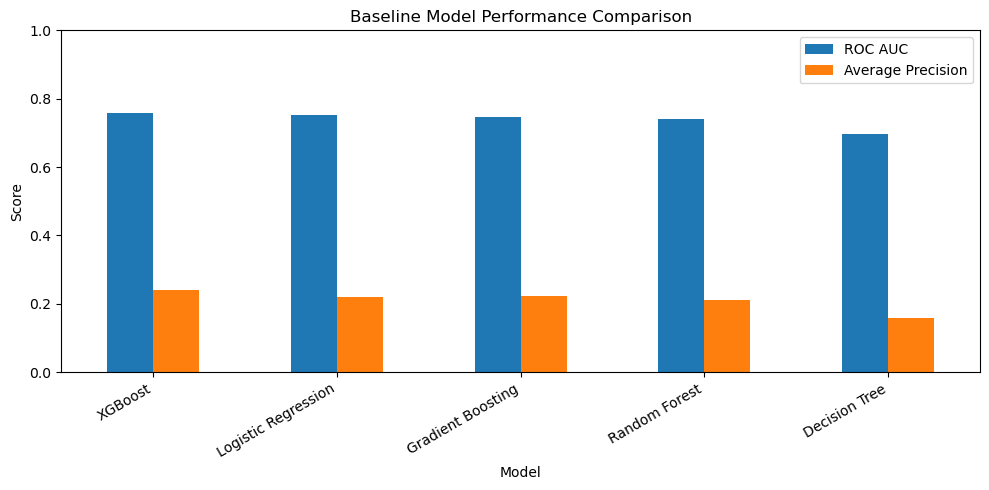

In [50]:
# Final baseline model comparison

comparison = results_df[
    ["Model", "ROC AUC", "Average Precision"]
].copy()

display(comparison.round(4))

comparison.set_index("Model")[
    ["ROC AUC", "Average Precision"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Baseline Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 17. Future Improvements
- Validate with a time-based split or newer applications to test performance on future customers.
- Evaluate calibration and choose thresholds using documented business costs.
- Add repayment-history features that capture missed payments and lateness, while ensuring they are available at application time.
- Compare undersampling with class weights and other imbalance strategies.
- Assess fairness and performance across relevant customer groups; investigate potential proxy variables.
- Use SHAP or other explainability methods and document their limitations.
- Package preprocessing and the model into a reproducible inference pipeline, then monitor drift and performance after deployment.